In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

pandas: 3.0.6
scikit-learn: 1.9.1


In [2]:
import pandas as pd

df = pd.read_csv("data/train.csv")
print(df.shape)
df.head()

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [4]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [5]:
missing = df.isnull().sum().sort_values(ascending=False)
missing[missing > 0]

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
GarageYrBlt       81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

In [6]:
df["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

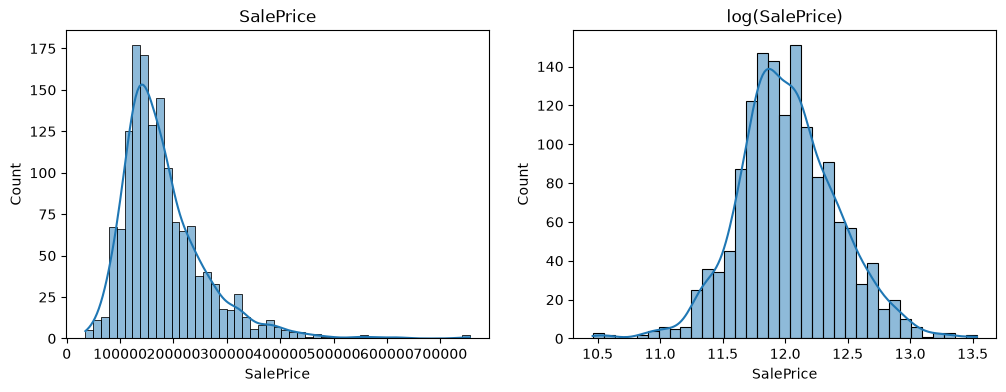

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("SalePrice")
sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=axes[1])
axes[1].set_title("log(SalePrice)")
plt.show()

In [8]:
corr = df.corr(numeric_only=True)["SalePrice"].sort_values(ascending=False)
corr.head(11)

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64

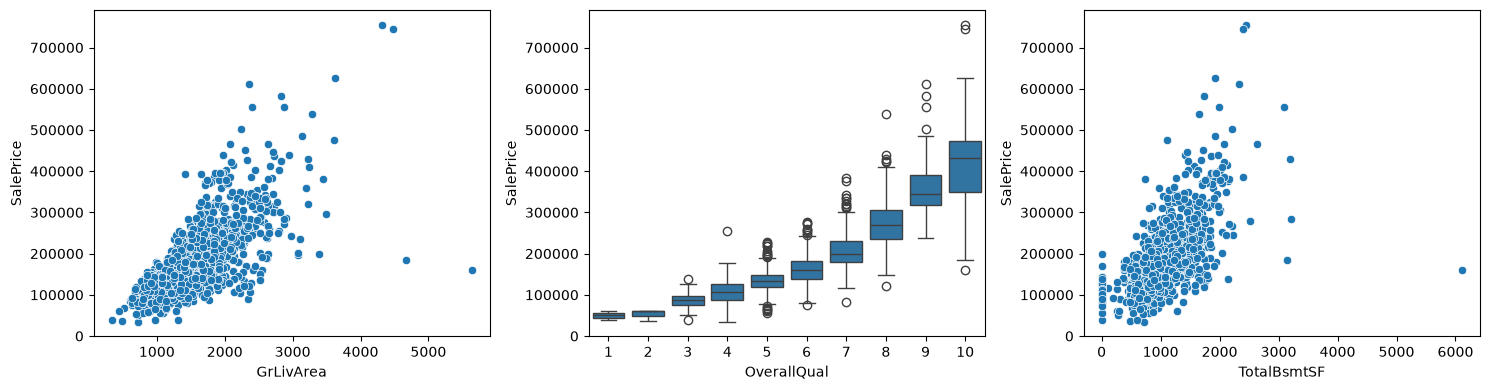

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.scatterplot(x="GrLivArea", y="SalePrice", data=df, ax=axes[0])
sns.boxplot(x="OverallQual", y="SalePrice", data=df, ax=axes[1])
sns.scatterplot(x="TotalBsmtSF", y="SalePrice", data=df, ax=axes[2])
plt.tight_layout()
plt.show()

In [10]:
df = df[~((df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000))].copy()
df.shape

(1458, 81)

In [11]:
# NaN means "this house doesn't have it"
none_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
             "BsmtFinType2", "MasVnrType"]
for c in none_cols:
    df[c] = df[c].fillna("None")

# numeric: no garage or no masonry means 0
for c in ["GarageYrBlt", "MasVnrArea"]:
    df[c] = df[c].fillna(0)

# LotFrontage: median of the same neighborhood
df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(
    lambda s: s.fillna(s.median()))

# Electrical: most common value
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])

df.isnull().sum().sum()

np.int64(0)

In [12]:
y = np.log1p(df["SalePrice"])
X = df.drop(columns=["SalePrice", "Id"])
print(X.shape, y.shape)

(1458, 79) (1458,)


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# MSSubClass is a category code stored as a number
X["MSSubClass"] = X["MSSubClass"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(1166, 79) (292, 79)


In [14]:
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

model = Pipeline([
    ("prep", preprocess),
    ("reg", LinearRegression()),
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](79,)","['MSSubClass','MSZoning','LotFrontage',...,'YrSold','SaleType', 'SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,79
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsi

In [15]:
pred = model.predict(X_test)

print("R2:   ", round(r2_score(y_test, pred), 4))
print("RMSE (log):", round(root_mean_squared_error(y_test, pred), 4))
print("MAE ($):   ", round(mean_absolute_error(np.expm1(y_test), np.expm1(pred))))

R2:    0.8821
RMSE (log): 0.141
MAE ($):    15529


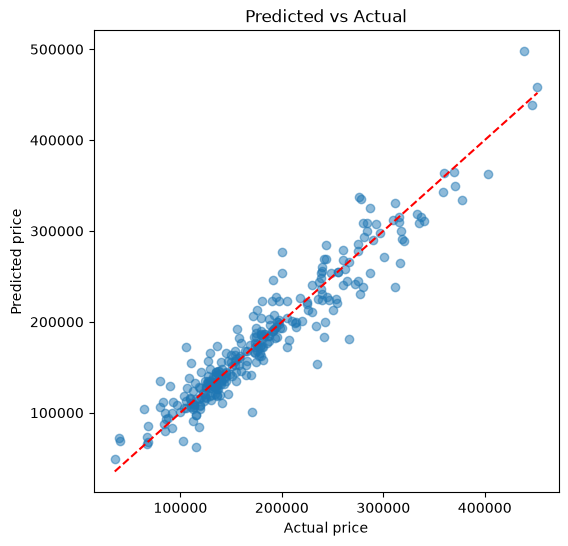

In [16]:
actual = np.expm1(y_test)
predicted = np.expm1(pred)

plt.figure(figsize=(6, 6))
plt.scatter(actual, predicted, alpha=0.5)
lims = [actual.min(), actual.max()]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Predicted vs Actual")
plt.show()

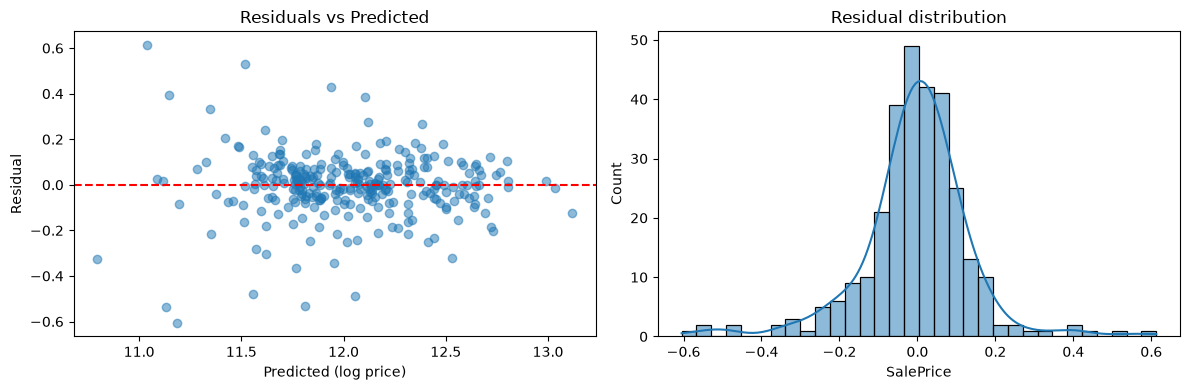

In [17]:
residuals = y_test - pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(pred, residuals, alpha=0.5)
axes[0].axhline(0, color="r", linestyle="--")
axes[0].set_xlabel("Predicted (log price)")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs Predicted")

sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title("Residual distribution")
plt.tight_layout()
plt.show()

In [18]:
errors = pd.DataFrame({"actual": actual, "predicted": predicted.round(0)})
errors["error"] = (errors["actual"] - errors["predicted"]).abs()
errors.sort_values("error", ascending=False).head(5)

,actual,predicted,error
747,265979.0,180992.0,84987.0
1158,235128.0,153361.0,81767.0
529,200624.0,276370.0,75746.0
218,311500.0,238840.0,72660.0
1170,171000.0,100441.0,70559.0


In [19]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import cross_val_score, KFold, GridSearchCV

def make_pipe(reg):
    return Pipeline([("prep", preprocess), ("reg", reg)])

kf = KFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "Linear": LinearRegression(),
    "Ridge (alpha=10)": Ridge(alpha=10),
    "Lasso (alpha=0.001)": Lasso(alpha=0.001, max_iter=10000),
}
for name, reg in models.items():
    scores = cross_val_score(make_pipe(reg), X_train, y_train,
                             cv=kf, scoring="neg_root_mean_squared_error")
    print(f"{name}: RMSE = {-scores.mean():.4f} (+/- {scores.std():.4f})")

Linear: RMSE = 0.1302 (+/- 0.0120)
Ridge (alpha=10): RMSE = 0.1116 (+/- 0.0103)
Lasso (alpha=0.001): RMSE = 0.1125 (+/- 0.0092)


In [20]:
ridge_grid = GridSearchCV(make_pipe(Ridge()),
    {"reg__alpha": [0.1, 1, 3, 10, 30, 100]},
    cv=kf, scoring="neg_root_mean_squared_error")
ridge_grid.fit(X_train, y_train)

lasso_grid = GridSearchCV(make_pipe(Lasso(max_iter=10000)),
    {"reg__alpha": [0.0003, 0.001, 0.003, 0.01]},
    cv=kf, scoring="neg_root_mean_squared_error")
lasso_grid.fit(X_train, y_train)

print("Ridge:", ridge_grid.best_params_, round(-ridge_grid.best_score_, 4))
print("Lasso:", lasso_grid.best_params_, round(-lasso_grid.best_score_, 4))

Ridge: {'reg__alpha': 10} 0.1116
Lasso: {'reg__alpha': 0.0003} 0.1109


In [21]:
for name, g in [("Ridge", ridge_grid), ("Lasso", lasso_grid)]:
    p = g.predict(X_test)
    print(name,
          "| R2:", round(r2_score(y_test, p), 4),
          "| RMSE(log):", round(root_mean_squared_error(y_test, p), 4),
          "| MAE($):", round(mean_absolute_error(np.expm1(y_test), np.expm1(p))))

Ridge | R2: 0.9104 | RMSE(log): 0.1229 | MAE($): 14331
Lasso | R2: 0.9177 | RMSE(log): 0.1178 | MAE($): 14057


In [22]:
best = lasso_grid.best_estimator_
names = best.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(best.named_steps["reg"].coef_, index=names)

print("Features kept:   ", (coefs != 0).sum())
print("Features dropped:", (coefs == 0).sum())

Features kept:    142
Features dropped: 170


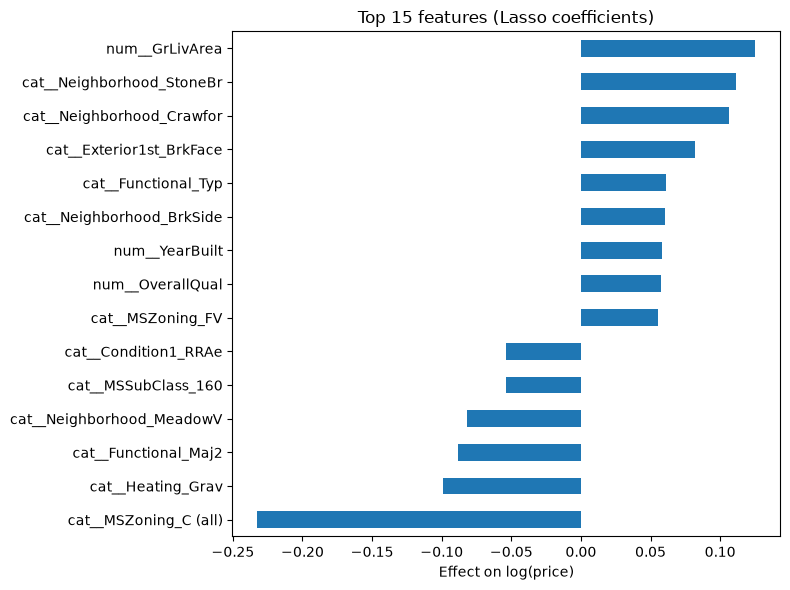

In [23]:
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)

top.sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Top 15 features (Lasso coefficients)")
plt.xlabel("Effect on log(price)")
plt.tight_layout()
plt.show()

In [24]:
top.round(3)

cat__MSZoning_C (all)       -0.232
num__GrLivArea               0.125
cat__Neighborhood_StoneBr    0.112
cat__Neighborhood_Crawfor    0.106
cat__Heating_Grav           -0.099
cat__Functional_Maj2        -0.088
cat__Exterior1st_BrkFace     0.082
cat__Neighborhood_MeadowV   -0.082
cat__Functional_Typ          0.061
cat__Neighborhood_BrkSide    0.060
num__YearBuilt               0.058
num__OverallQual             0.057
cat__MSZoning_FV             0.056
cat__MSSubClass_160         -0.054
cat__Condition1_RRAe        -0.054
dtype: float64

In [25]:
import joblib, os

os.makedirs("models", exist_ok=True)
final_model = lasso_grid.best_estimator_
joblib.dump(final_model, "models/lasso_house_price.joblib")

['models/lasso_house_price.joblib']

In [26]:
loaded = joblib.load("models/lasso_house_price.joblib")
sample = X_test.iloc[[0]]
print("Predicted: $", round(np.expm1(loaded.predict(sample))[0]))
print("Actual:    $", round(np.expm1(y_test.iloc[0])))

Predicted: $ 221457
Actual:    $ 190000


In [27]:
p_loaded = loaded.predict(X_test)
p_memory = lasso_grid.best_estimator_.predict(X_test)
print("Identical:", np.allclose(p_loaded, p_memory))
print("R2 from loaded model:", round(r2_score(y_test, p_loaded), 4))

Identical: True
R2 from loaded model: 0.9177
